<!--
SPDX-FileCopyrightText: 2026 Yue Jiaming
SPDX-License-Identifier: MIT
-->

# USB CT: sparse-view 3D reconstruction

**Author:** Yue Jiaming  
**CIL version:** 26.0.0  
**Dataset:** [HDTomo TXRM micro-CT datasets](https://doi.org/10.5281/zenodo.4822516), USB scan (`usb.zip`), Jørgensen, Andersen and Gundlach (2021). The scan is downloaded separately using CIL's data utilities.

**Contributions:**

- Integrate FaCT-GS with the CIL preprocessing workflow.
- Compare FDK, SIRT and FaCT-GS using shared 25-, 50- and 75-view splits.
- Evaluate central slices and training/test projection PSNR and SSIM.

**License:** [MIT](LICENSE.txt) for original contributions; [third-party code and data retain their own terms](#Licensing-and-references).

This example compares FDK, SIRT and FaCT-GS on a USB cone-beam CT scan using 25, 50 and 75 training views. A shared set of 20 held-out views evaluates projection consistency.

**Overview**

1. **Environment setup**: install CIL, PyTorch and CUDA extensions.
2. **Data and preprocessing**: read the USB scan, preprocess projections, split views and construct the geometry.
3. **Reconstruction methods**: run FDK, SIRT and FaCT-GS.
4. **Compare results**: inspect central slices and compute training and test projection PSNR/SSIM.
5. **Compare view counts**: compare reconstructions from 25, 50 and 75 views.

The notebook closes with a summary and plans for future work.


## 1. Environment setup

This implementation uses **Python 3.10, PyTorch 2.4.1 (`cu118`), CUDA Toolkit 11.8 and GCC/G++ 11**. Run these Linux commands from the notebook directory, in the same terminal.

### 1.1 Create and check the build environment

| Component | Setup used here | If installation or a version change is needed |
| --- | --- | --- |
| NVIDIA driver | CUDA 11.8 release baseline: Linux ≥520.61.05; newer compatible drivers are fine. | Select your GPU and OS on the [NVIDIA driver download page](https://www.nvidia.com/en-us/drivers/). |
| Host compiler | GCC/G++ 11, installed with Conda below. | For another compiler version, check [CUDA 11.8 compiler support](https://docs.nvidia.com/cuda/archive/11.8.0/cuda-installation-guide-linux/index.html#system-requirements) before following the [GCC installation guide](https://gcc.gnu.org/install/). |
| PyTorch | 2.4.1 with CUDA 11.8 (`cu118`). | Select the matching PyTorch/CUDA build from the [official installation commands](https://pytorch.org/get-started/locally/). |

Keep the versions below for reproducing this example. If changing versions, check CUDA, compiler and PyTorch compatibility together.

```bash
# Create the environment once, then activate it.
conda create -n usb-showcase python=3.10 pip -y
conda activate usb-showcase
# Check the driver version against the requirement above.
nvidia-smi
# Install and select GCC/G++ 11 for the extension builds.
conda install -c conda-forge gcc_linux-64=11 gxx_linux-64=11 -y
export CC="$CONDA_PREFIX/bin/x86_64-conda-linux-gnu-cc"
export CXX="$CONDA_PREFIX/bin/x86_64-conda-linux-gnu-c++"
export CUDAHOSTCXX="$CXX"
# Install the CUDA compiler and development libraries.
conda install -c nvidia/label/cuda-11.8.0 cuda-toolkit -y
export CUDA_HOME="$CONDA_PREFIX"
export PATH="$CUDA_HOME/bin:$PATH"
nvcc --version  # Expected: release 11.8
"$CXX" --version  # Expected: GCC 11.x
```

Skip `conda create` if the environment already exists. `nvidia-smi` reports the driver's supported CUDA version; `nvcc --version` reports the installed Toolkit version. Reapply the compiler and CUDA exports in each new terminal before building extensions.

### 1.2 Install dependencies, download FaCT-GS and compile submodules

```bash
# Install the CUDA 11.8 PyTorch build, then the remaining Python dependencies.
python -m pip install torch==2.4.1 torchvision==0.19.1 --index-url https://download.pytorch.org/whl/cu118
python -m pip install -r requirements.txt --index-url https://pypi.org/simple
# Download the pinned source, its pinned submodules, and apply the USB hooks.
(
    set -e
    FACTGS_DIR="$PWD/third_party/fact-gs"
    PATCH_FILE="$PWD/third_party/usb_hooks.patch"
    if [ ! -d "$FACTGS_DIR/.git" ]; then
        git clone --no-checkout https://github.com/PaPieta/fact-gs.git "$FACTGS_DIR"
    fi
    git -C "$FACTGS_DIR" checkout --detach 9b95ea9370055d9caf148899775173a3bdfe6d61
    git -C "$FACTGS_DIR" submodule update --init --recursive --jobs 4
    # A second installation reuses an already-applied patch.
    if ! git -C "$FACTGS_DIR" apply --reverse --check "$PATCH_FILE" 2>/dev/null; then
        git -C "$FACTGS_DIR" apply --check "$PATCH_FILE"
        git -C "$FACTGS_DIR" apply "$PATCH_FILE"
    fi
    # Build the extensions with the compilers selected above.
    MODULES_DIR="$FACTGS_DIR/fact_gs/submodules"
    export GLM_HOME="$MODULES_DIR/glm"
    export MAX_JOBS=2
    for module in TIGRE simple_knn fused_3d_tv fused_ssim gs_ct_rasterizer gs_voxelizer; do
        # TIGRE invokes nvcc directly and needs an explicit host compiler.
        if [ "$module" = TIGRE ]; then
            export NVCC_PREPEND_FLAGS="-ccbin $CXX"
        else
            unset NVCC_PREPEND_FLAGS
        fi
        python -m pip install --no-build-isolation "$MODULES_DIR/$module"
    done
)
```

Select the **Python kernel for `usb-showcase`** before running Section 2. To run only FDK/SIRT in an existing CIL/TIGRE environment, leave FaCT-GS disabled. Git and internet access are required for installation. The fixed FaCT-GS commit pins all seven submodules; the downloaded source is stored in `third_party/fact-gs` and excluded from Git.


## 2. Data and preprocessing

### 2.1 Configuration

Set the data directory, training view count `VIEWS`, GPU and method switches. After changing `VIEWS`, rerun from Section 2.3. Section 5 runs the 25-, 50- and 75-view experiments in a batch.


In [1]:
from pathlib import Path
import os, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CASE = Path.cwd().resolve()
DATA_DIR = CASE / 'dataset'  # Directory for downloaded CIL example data
VIEWS = 25 # 25, 50, 75
GPU = '0'  # Select an available GPU; restart the kernel after changing this.
RUN_FDK = True
RUN_SIRT = True
RUN_FACTGS = True
RUN_METRICS = True
os.environ['CUDA_VISIBLE_DEVICES'] = GPU
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '1'

# Volumes from this run; rerunning this cell clears them.
reconstructed_volumes = {}


### 2.2 Read and preprocess the data

Download or read the USB example dataset with CIL's `dataexample.USB`. The reader applies reference-image normalisation and pixel-shift correction. Take the negative logarithm of transmission, crop 200 pixels from each horizontal edge, then average 4×4 blocks and update the detector pixel spacing.


In [2]:
from cil.utilities import dataexample
from cil.processors import TransmissionAbsorptionConverter, Slicer

# Download the USB example once; skip if its directory already exists.
dataexample.USB.download_data(str(DATA_DIR), prompt=False)

# Read all transmission projections and keep the first view for comparison.
transmission = dataexample.USB.get(str(DATA_DIR))
before = transmission.get_slice(angle=0).as_array().copy()

# Convert transmission to attenuation line integrals with one negative logarithm.
absorption = TransmissionAbsorptionConverter(
    white_level=1.0, min_intensity=1e-6, accelerated=False,
)(transmission)

# Crop 200 pixels from each horizontal edge, preserving CIL data and geometry.
preprocessed = Slicer(roi={'horizontal': (200, -200)})(absorption)
# Average 4x4 blocks and update the detector geometry accordingly.
from cil.framework import AcquisitionData
cropped = preprocessed.as_array()
count, height, width = cropped.shape
averaged = cropped.reshape(count, height // 4, 4, width // 4, 4).mean(axis=(2, 4))
geometry = preprocessed.geometry.copy()
geometry.set_panel([width // 4, height // 4],
                   pixel_size=[geometry.pixel_size_h * 4, geometry.pixel_size_v * 4],
                   origin=geometry.config.panel.origin)
preprocessed = AcquisitionData(averaged, geometry=geometry)
after = preprocessed.get_slice(angle=0).as_array()


Dataset folder already exists in /home/yjm/USB-Sparse-View/dataset


#### Before and after preprocessing

Left: transmission. Right: preprocessed attenuation line integrals, with a separate colour scale. Orange dashed lines mark the crop boundaries.


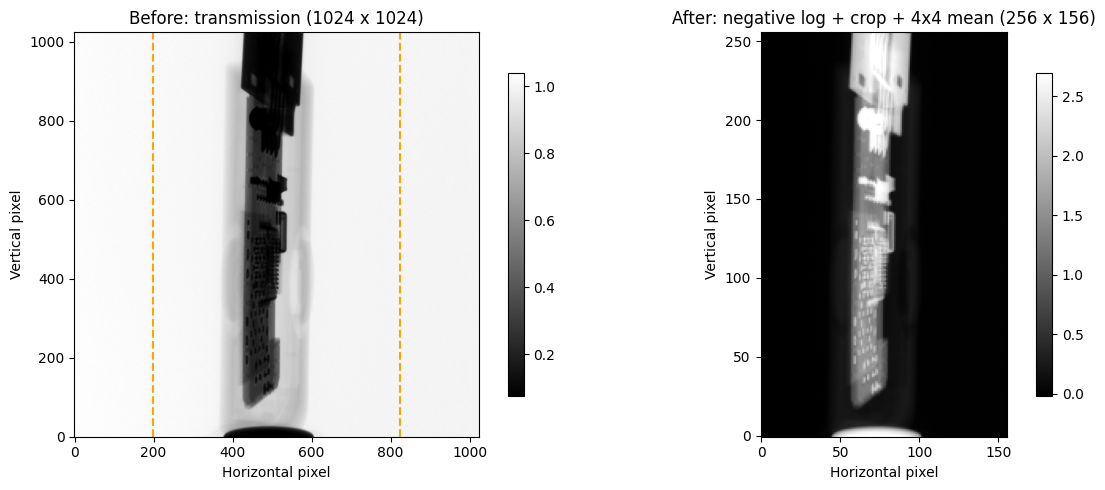

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, image, title in zip(
    axes, [before, after],
    ['Before: transmission', 'After: negative log + crop + 4x4 mean'],
):
    low, high = np.percentile(image, [1, 99])
    im = ax.imshow(image, cmap='gray', origin='lower', vmin=low, vmax=high)
    ax.set_title(f'{title} ({image.shape[0]} x {image.shape[1]})')
    ax.set_xlabel('Horizontal pixel')
    ax.set_ylabel('Vertical pixel')
    fig.colorbar(im, ax=ax, shrink=0.8)

axes[0].axvline(199.5, color='orange', linestyle='--')
axes[0].axvline(before.shape[1] - 200.5, color='orange', linestyle='--')
plt.tight_layout()
plt.show()


### 2.3 Split training and test views

Select 25, 50 or 75 evenly spaced training views, excluding the near-duplicate 360° endpoint. All three experiments share 20 test views that are disjoint from every training set.


In [4]:
# Fixed original view indices, matching the historical experiments.
train_splits = {75: [0, 11, 21, 32, 43, 53, 64, 75, 85, 96, 107, 117, 128, 139, 149, 160, 171, 181, 192, 203, 213, 224, 235, 245, 256, 267, 277, 288, 299, 309, 320, 331, 341, 352, 363, 373, 384, 395, 405, 416, 427, 437, 448, 459, 469, 480, 491, 501, 512, 523, 533, 544, 555, 565, 576, 587, 597, 608, 619, 629, 640, 651, 661, 672, 683, 693, 704, 715, 725, 736, 747, 757, 768, 779, 789], 50: [0, 16, 32, 48, 64, 80, 96, 112, 128, 144, 160, 176, 192, 208, 224, 240, 256, 272, 288, 304, 320, 336, 352, 368, 384, 400, 416, 432, 448, 464, 480, 496, 512, 528, 544, 560, 576, 592, 608, 624, 640, 656, 672, 688, 704, 720, 736, 752, 768, 784], 25: [0, 32, 64, 96, 128, 160, 192, 224, 256, 288, 320, 352, 384, 416, 448, 480, 512, 544, 576, 608, 640, 672, 704, 736, 768]}
train_indices = np.asarray(train_splits[VIEWS])
test_indices = np.asarray([1, 41, 84, 126, 168, 210, 252, 294, 337, 379, 420, 462, 505, 547, 589, 631, 673, 714, 758, 799])
assert len(train_indices) == VIEWS and len(test_indices) == 20
assert not np.intersect1d(train_indices, test_indices).size
print('Training views:', len(train_indices), '| Test views:', len(test_indices))

# Subsequent reconstruction uses the in-memory data from Section 2.
projections = preprocessed.as_array()
angles = np.asarray(preprocessed.geometry.angles)


Training views: 25 | Test views: 20


### 2.4 Reconstruction geometry

#### Training projections and angles

Extract projections at the training indices and update the angles in the acquisition geometry.


In [5]:
def select_training_data(preprocessed, indices):
    from cil.framework import AcquisitionData
    geometry = preprocessed.geometry.copy()
    geometry.set_angles(preprocessed.geometry.angles[indices],
                        initial_angle=geometry.config.angles.initial_angle,
                        angle_unit=geometry.config.angles.angle_unit)
    return AcquisitionData(preprocessed.as_array()[indices].copy(), geometry=geometry)

data = select_training_data(preprocessed, train_indices)


#### Voxel grid

Use the detector coverage and magnification to determine the reconstruction region. Set the longest side to 128 voxels and scale the other dimensions proportionally.


In [6]:
def make_volume_grid(ag):
    from cil.framework import ImageGeometry
    width, height = ag.pixel_num_h, ag.pixel_num_v
    sizes = np.array([width * ag.pixel_size_h, width * ag.pixel_size_h,
                      height * ag.pixel_size_v]) / ag.magnification
    counts = np.maximum(2, np.rint(sizes / max(sizes) * 128).astype(int))
    spacing = sizes / counts
    ig = ImageGeometry(voxel_num_x=int(counts[0]), voxel_num_y=int(counts[1]),
                       voxel_num_z=int(counts[2]), voxel_size_x=spacing[0],
                       voxel_size_y=spacing[1], voxel_size_z=spacing[2])
    return ig, sizes, counts

ig, sizes, counts = make_volume_grid(data.geometry)


#### Coordinate scale

Following the historical experiments, normalise the longest side of the reconstruction region to 2, scaling the acquisition geometry and voxel spacing together. Reconstructed attenuation coefficients are expressed in inverse normalised length units.


In [7]:
def normalize_geometry(data, sizes, counts):
    from cil.framework import AcquisitionData, ImageGeometry
    geometry_scale = 2 / max(sizes)
    ag = data.geometry.copy()
    for component in (ag.config.system.source, ag.config.system.detector,
                      ag.config.system.rotation_axis):
        component.position = component.position * geometry_scale
    ag.config.panel.pixel_size *= geometry_scale
    ag.config.units = 'normalized distance'
    spacing = sizes * geometry_scale / counts
    ig = ImageGeometry(voxel_num_x=int(counts[0]), voxel_num_y=int(counts[1]),
                       voxel_num_z=int(counts[2]), voxel_size_x=spacing[0],
                       voxel_size_y=spacing[1], voxel_size_z=spacing[2])
    data = AcquisitionData(data.as_array().copy(), geometry=ag)
    return data, ig

data, ig = normalize_geometry(data, sizes, counts)


## 3. Reconstruction methods

### 3.1 FDK

FDK is an analytical cone-beam CT reconstruction method, called here through CIL/TIGRE's `FBP`.


In [8]:
def reconstruct_fdk(data, ig):
    from cil.plugins.tigre import FBP
    assert data is not None, 'Run the geometry setup cells first.'
    start = time.perf_counter()
    fdk = FBP(ig, data.geometry)(data)
    elapsed = time.perf_counter() - start
    fdk_volume = np.asarray(fdk.as_array(), dtype=np.float32)
    return fdk_volume

if RUN_FDK:
    reconstructed_volumes['fdk'] = reconstruct_fdk(data, ig)


#### FDK central slices


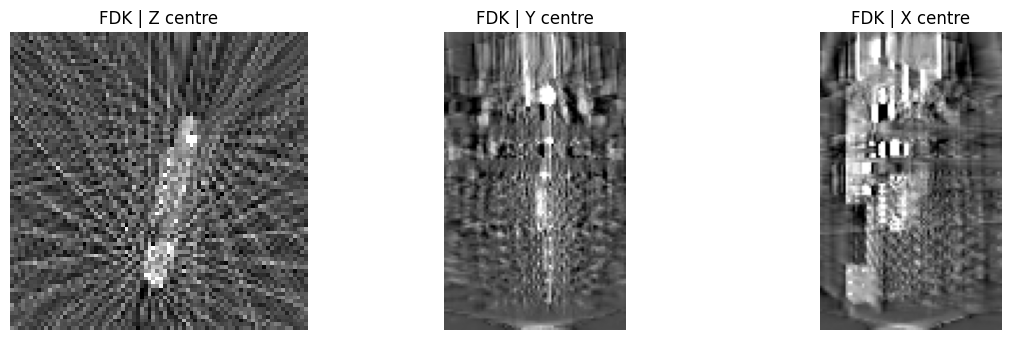

In [9]:
if RUN_FDK:
    methods = ['fdk']
    volumes = {m: reconstructed_volumes[m] for m in methods if m in reconstructed_volumes}
    if volumes:
        low, high = np.percentile(np.concatenate([v.ravel()[::16] for v in volumes.values()]), [1, 99.5])
        fig, axes = plt.subplots(len(volumes), 3, figsize=(12, 3.5 * len(volumes)), squeeze=False)
        for row, (method, volume) in enumerate(volumes.items()):
            for axis, label in enumerate(['Z', 'Y', 'X']):
                view = np.take(volume, volume.shape[axis] // 2, axis=axis)
                axes[row, axis].imshow(view, cmap='gray', origin='lower', vmin=low, vmax=high)
                axes[row, axis].set_title(f'{method.upper()} | {label} centre')
                axes[row, axis].axis('off')
        plt.tight_layout()
        plt.show()


### 3.2 SIRT

Start from a zero volume and run 1000 iterations with a nonnegativity constraint. Compute the projection residual `0.5 * sum((Ax-b)**2)` every 10 iterations and plot the corresponding mean squared error.


In [10]:
def reconstruct_sirt(data, ig, iterations=1000):
    from cil.plugins.tigre import ProjectionOperator
    from cil.optimisation.algorithms import SIRT
    assert data is not None, 'Run the geometry setup cells first.'
    class ResidualSIRT(SIRT):
        def update_objective(self):
            residual = self.operator.direct(self.solution).as_array().astype(np.float64)
            residual -= self.data.as_array()
            self.loss.append(float(0.5 * np.sum(residual**2)))
            if not hasattr(self, 'loss_iterations'):
                self.loss_iterations = []
            self.loss_iterations.append(max(0, self.iteration))

    start = time.perf_counter()
    operator = ProjectionOperator(ig, data.geometry)
    solver = ResidualSIRT(initial=ig.allocate(0), operator=operator, data=data,
                          lower=0, update_objective_interval=10)
    def progress(algorithm):
        if algorithm.iteration % 100 == 0:
            print(f'SIRT iteration {algorithm.iteration}/{iterations}', flush=True)
    solver.run(iterations, callbacks=[progress], verbose=0)
    if solver.loss_iterations[-1] != solver.iteration:
        solver.update_objective()
    history = dict(iterations=solver.loss_iterations, loss=solver.loss,
                   projection_pixels=int(data.as_array().size),
                   definition='0.5 * sum((A x - b)^2), recomputed at current solution')
    elapsed = time.perf_counter() - start
    sirt_volume = np.asarray(solver.solution.as_array(), dtype=np.float32)
    return sirt_volume, history

if RUN_SIRT:
    reconstructed_volumes['sirt'], history = reconstruct_sirt(data, ig)


SIRT iteration 0/1000
SIRT iteration 100/1000
SIRT iteration 200/1000
SIRT iteration 300/1000
SIRT iteration 400/1000
SIRT iteration 500/1000
SIRT iteration 600/1000
SIRT iteration 700/1000
SIRT iteration 800/1000
SIRT iteration 900/1000
SIRT iteration 1000/1000


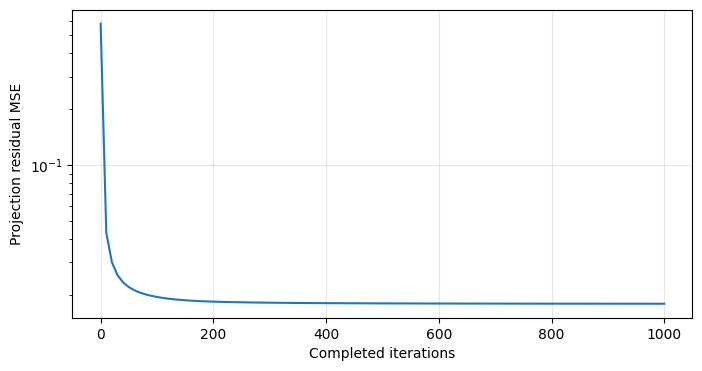

In [11]:
if RUN_SIRT:
    steps = np.asarray(history['iterations'])
    mse = 2 * np.asarray(history['loss']) / history['projection_pixels']
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.semilogy(steps, mse)
    ax.set(xlabel='Completed iterations', ylabel='Projection residual MSE')
    ax.grid(alpha=0.3)
    plt.show()

# Axes show completed iterations and projection residual mean squared error.


#### SIRT central slices


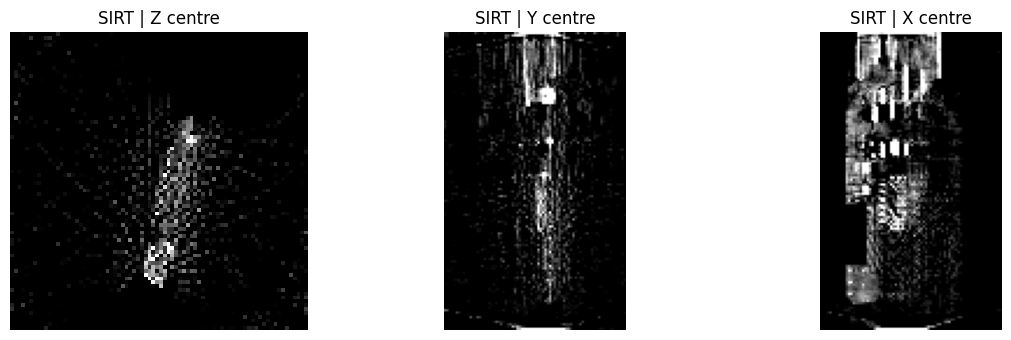

In [12]:
if RUN_SIRT:
    methods = ['sirt']
    volumes = {m: reconstructed_volumes[m] for m in methods if m in reconstructed_volumes}
    if volumes:
        low, high = np.percentile(np.concatenate([v.ravel()[::16] for v in volumes.values()]), [1, 99.5])
        fig, axes = plt.subplots(len(volumes), 3, figsize=(12, 3.5 * len(volumes)), squeeze=False)
        for row, (method, volume) in enumerate(volumes.items()):
            for axis, label in enumerate(['Z', 'Y', 'X']):
                view = np.take(volume, volume.shape[axis] // 2, axis=axis)
                axes[row, axis].imshow(view, cmap='gray', origin='lower', vmin=low, vmax=high)
                axes[row, axis].set_title(f'{method.upper()} | {label} centre')
                axes[row, axis].axis('off')
        plt.tight_layout()
        plt.show()


### 3.3 FaCT-GS

Pass the training projections and geometry to the trainer in `third_party/fact-gs`.

#### Method background

FaCT-GS (Fast and Scalable CT Reconstruction with Gaussian Splatting), proposed by **Pawel Tomasz Pieta, Jakob Sauer Jørgensen and co-authors**, was published at **ECCV 2026**. It represents the attenuation field with optimisable 3D Gaussians and fits their parameters to measured X-ray projections. The paper focuses on the efficiency and scalability of projection rendering and voxelisation. [Paper](https://arxiv.org/abs/2604.01844) · [Official code](https://github.com/PaPieta/fact-gs)

**Representation.** The object is a sum of 3D Gaussians with different positions, sizes, orientations and densities:

$$
\mu(\mathbf{x}) = \sum_i \rho_i\exp\!\left[-\frac12(\mathbf{x}-\mathbf{p}_i)^\top\Sigma_i^{-1}(\mathbf{x}-\mathbf{p}_i)\right].
$$

Here $\mathbf{p}_i$ is position, $\rho_i$ is density amplitude and $\Sigma_i$ describes shape and orientation. These Gaussian parameters are optimised.

**From projections to a volume.** First reconstruct an FDK volume from the training projections, then sample initial Gaussians using its gradients. Repeatedly render a projection, compare it with the measured projection and backpropagate to update the Gaussians, with densification and pruning as configured. Finally, sample the Gaussian field onto a voxel grid to display 3D slices.

This example uses the upstream implementation's objective:

$$
\mathcal{L}=\mathcal{L}_{1}(\hat P,P)+0.3\,[1-\operatorname{SSIM}(\hat P,P)]+0.05\,\operatorname{TV}(\mu).
$$

The first two terms enforce projection consistency. TV penalises spatial variation and is evaluated on randomly sampled $32^3$ subvolumes in this implementation. Training uses only the training views; test views are reserved for evaluation.


#### Training parameters

Use the GPU selected in Section 2.1, with 20000 training steps and 10000 initial Gaussians. `FACTGS_OUTPUT` specifies the directory for saved models and volumes.


In [13]:
FACTGS_STEPS = 20000
FACTGS_GAUSSIANS = 10000
FACTGS_OUTPUT = CASE / 'runs_notebook' / f'{VIEWS}views_factgs'

def load_factgs():
    import sys
    repo = CASE / 'third_party/fact-gs'
    if str(repo) not in sys.path:
        sys.path.insert(0, str(repo))
    os.environ['GLM_HOME'] = str(repo / 'fact_gs/submodules/glm')
    import tigre  # Import TIGRE before PyTorch.
    import torch
    return repo

if RUN_FACTGS:
    load_factgs()


#### Convert scanner geometry

Use CIL's TIGRE interface to convert distances, detector parameters and angles, and arrange voxel dimensions in XYZ order. This adapter supports circular cone-beam trajectories without tilt or offsets.


In [14]:
def make_factgs_scanner(data, ig, angles):
    from cil.plugins.tigre.Geometry import CIL2TIGREGeometry
    all_geometry = data.geometry.copy()
    all_geometry.set_angles(angles,
                            initial_angle=data.geometry.config.angles.initial_angle,
                            angle_unit=data.geometry.config.angles.angle_unit)
    geo, gaussian_angles = CIL2TIGREGeometry.getTIGREGeometry(ig, all_geometry)
    for offset in (geo.rotDetector, geo.offDetector, geo.offOrigin):
        if not np.allclose(offset, 0, atol=1e-6):
            raise ValueError('This FaCT-GS camera adapter supports only circular trajectories without tilt or offsets.')
    if not np.isclose(max(geo.sVoxel), 2):
        raise ValueError('Run Section 2.4 first to normalise the longest dimension to 2.')
    scanner = dict(
        mode='cone', DSO=float(geo.DSO), DSD=float(geo.DSD),
        nDetector=geo.nDetector.tolist(), sDetector=geo.sDetector.tolist(),
        dDetector=geo.dDetector.tolist(), nVoxel=geo.nVoxel[::-1].tolist(),
        sVoxel=geo.sVoxel[::-1].tolist(), dVoxel=geo.dVoxel[::-1].tolist(),
        offOrigin=[0, 0, 0], offDetector=[0, 0], accuracy=0.5, filter=None,
    )

    return scanner, gaussian_angles

if RUN_FACTGS:
    scanner, gaussian_angles = make_factgs_scanner(data, ig, angles)


#### Camera interface

Build a camera pose and projection for each training and test view. Flip projections vertically to match the FaCT-GS camera convention, then restore the CIL orientation after rendering.

`cil_scene_reader` supplies camera lists and scanner parameters to the trainer; the 3D ground truth is set to `None`.


In [15]:
def make_factgs_reader(scanner, gaussian_angles, projections, train_indices, test_indices):
    from fact_gs.r2_gaussian.dataset.dataset_readers import CameraInfo, SceneInfo, angle2pose
    camera_infos = {'train': [], 'test': []}
    fov_x = 2 * np.arctan2(scanner['sDetector'][1] / 2, scanner['DSD'])
    fov_y = 2 * np.arctan2(scanner['sDetector'][0] / 2, scanner['DSD'])
    for subset, indices in [('train', train_indices), ('test', test_indices)]:
        uid_offset = 0 if subset == 'train' else len(train_indices)
        for order, index in enumerate(indices):
            angle = float(gaussian_angles[index])
            world_to_camera = np.linalg.inv(angle2pose(scanner['DSO'], angle))
            camera_infos[subset].append(CameraInfo(
                uid=uid_offset + order,
                R=world_to_camera[:3, :3].T, T=world_to_camera[:3, 3],
                angle=angle, FovY=fov_y, FovX=fov_x,
                image=np.ascontiguousarray(projections[index, ::-1], dtype=np.float32),
                image_path=None, image_name=f'{int(index):04d}',
                width=scanner['nDetector'][1], height=scanner['nDetector'][0],
                mode=1, scanner_cfg=scanner,
            ))

    def cil_scene_reader(_path, evaluate):
        return SceneInfo(camera_infos['train'], camera_infos['test'] if evaluate else [],
                         None, scanner, 1.0)

    return cil_scene_reader

if RUN_FACTGS:
    cil_scene_reader = make_factgs_reader(scanner, gaussian_angles, projections, train_indices, test_indices)


#### Optimisation and training

Use FDK-gradient initialisation, random seed 0 and the loss `L1 + 0.3 × (1-SSIM) + 0.05 × TV`. The callback records training loss and returns the final scene. Models are saved to a new directory specified by `FACTGS_OUTPUT`.


In [16]:
def train_factgs(cil_scene_reader, output, steps=20000, gaussians=10000):
    import random, torch
    from tempfile import mkdtemp
    from hydra import compose, initialize_config_dir
    from train_recon import optimize
    repo = load_factgs()
    with initialize_config_dir(config_dir=str(repo / 'config'), version_base=None):
        factgs_config = compose(config_name='default_recon', overrides=['eval=eval_silent'])
    factgs_config.model.data_source_path = 'in_memory_usb'
    factgs_config.model.num_gaussians = gaussians
    factgs_config.model.init_mode = 'gradient'
    factgs_config.model.density_thresh = 0.01
    factgs_config.model.eval = True
    factgs_config.optim.steps = steps
    factgs_config.optim.lambda_dssim = 0.3
    factgs_config.optim.lambda_tv = 0.05
    factgs_history = []
    factgs_result = {}

    def collect_factgs_result(step, losses, training_seconds, evaluation_seconds,
                             max_steps, eval_args, scene, render, voxelize,
                             init_mode, force_eval=False):
        if step % 100 == 0 or step == max_steps:
            factgs_history.append((step, float(losses['loss_total'])))
        if step == max_steps:
            factgs_result['scene'] = scene
            factgs_result['training_seconds'] = training_seconds

    output.mkdir(parents=True, exist_ok=True)
    factgs_config.model.model_path = mkdtemp(prefix="run_", dir=str(output))
    random.seed(0)
    np.random.seed(0)
    torch.manual_seed(0)
    torch.cuda.set_device(0)  # The first GPU exposed by CUDA_VISIBLE_DEVICES.
    start = time.perf_counter()
    optimize(factgs_config, scene_reader=cil_scene_reader,
             report_callback=collect_factgs_result)
    print(f'FaCT-GS elapsed time: {time.perf_counter() - start:.3f} seconds')

    return factgs_result['scene'], factgs_history

if RUN_FACTGS:
    scene, factgs_history = train_factgs(cil_scene_reader, FACTGS_OUTPUT, FACTGS_STEPS, FACTGS_GAUSSIANS)


Loading Training Cameras
Loading Test Cameras
Data source path: in_memory_usb
Model save path: /home/yjm/USB-Sparse-View/runs_notebook/25views_factgs/run_3g7x4o7b
Initialize 10000 out of total 10000 Gaussians.
Using FDK reconstruction for initialization.
Reconstruction finished
Random sampling in an intensity volume using gradient as probability.
Initialize gaussians from 10000 estimated points
Use total variation loss


[STEP 20000] Saving Gaussians
FaCT-GS elapsed time: 145.087 seconds


#### Generate the volume and projections

Convert the volume from XYZ to ZYX and render the training and test projections. Store the results in `reconstructed_volumes` and `factgs_projections` for evaluation.


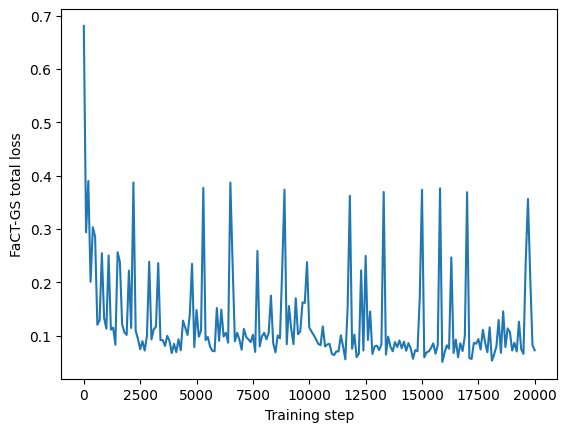

In [17]:
def render_factgs_results(scene, scanner, projections, train_indices, test_indices):
    import torch
    from fact_gs import rasterize_proj, voxelize_vol
    with torch.no_grad():
        volume_xyz = voxelize_vol(scene.gaussians, scanner['offOrigin'],
                                 scanner['nVoxel'], scanner['sVoxel'])['vol']
        volume = np.ascontiguousarray(
            volume_xyz.detach().cpu().numpy().transpose(2, 1, 0), dtype=np.float32)
        factgs_projections = {}
        for subset, indices, cameras in [
            ('train', train_indices, scene.getTrainCameras()),
            ('test', test_indices, scene.getTestCameras()),
        ]:
            by_index = {int(camera.image_name): camera for camera in cameras}
            predicted = []
            for index in indices:
                image = rasterize_proj(by_index[int(index)], scene.gaussians)['render']
                predicted.append(image.squeeze().detach().cpu().numpy()[::-1].copy())
            factgs_projections[subset] = (projections[indices], np.stack(predicted))
    return volume, factgs_projections

if RUN_FACTGS:
    reconstructed_volumes['factgs'], factgs_projections = render_factgs_results(
        scene, scanner, projections, train_indices, test_indices)
    steps, losses = np.asarray(factgs_history).T
    plt.plot(steps, losses)
    plt.xlabel('Training step')
    plt.ylabel('FaCT-GS total loss')
    plt.show()

def reconstruct_factgs(data, ig, angles, projections, train_indices, test_indices,
                       output, steps=20000, gaussians=10000):
    load_factgs()
    scanner, gaussian_angles = make_factgs_scanner(data, ig, angles)
    reader = make_factgs_reader(scanner, gaussian_angles, projections, train_indices, test_indices)
    scene, history = train_factgs(reader, output, steps, gaussians)
    return render_factgs_results(scene, scanner, projections, train_indices, test_indices)


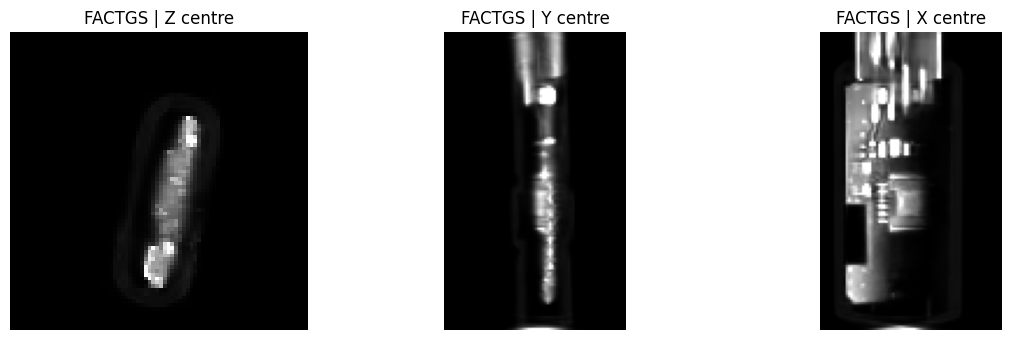

In [18]:
if RUN_FACTGS:
    methods = ['factgs']
    volumes = {m: reconstructed_volumes[m] for m in methods if m in reconstructed_volumes}
    if volumes:
        low, high = np.percentile(np.concatenate([v.ravel()[::16] for v in volumes.values()]), [1, 99.5])
        fig, axes = plt.subplots(len(volumes), 3, figsize=(12, 3.5 * len(volumes)), squeeze=False)
        for row, (method, volume) in enumerate(volumes.items()):
            for axis, label in enumerate(['Z', 'Y', 'X']):
                view = np.take(volume, volume.shape[axis] // 2, axis=axis)
                axes[row, axis].imshow(view, cmap='gray', origin='lower', vmin=low, vmax=high)
                axes[row, axis].set_title(f'{method.upper()} | {label} centre')
                axes[row, axis].axis('off')
        plt.tight_layout()
        plt.show()


## 4. Compare results

### 4.1 Projection evaluation

FDK/SIRT use CIL/TIGRE to forward-project the volume; FaCT-GS uses its Gaussian renderer. Compare predicted and measured projections at matching views.


In [19]:
def project_cil_volume(volume, data, ig, projections, angles, test_indices):
    from cil.plugins.tigre import ProjectionOperator
    test_geometry = data.geometry.copy()
    test_geometry.set_angles(angles[test_indices],
                            initial_angle=data.geometry.config.angles.initial_angle,
                            angle_unit=data.geometry.config.angles.angle_unit)
    image = ig.allocate(0)
    image.fill(volume)
    result = {}
    for subset, measured, geometry in [
        ('train', data.as_array(), data.geometry),
        ('test', projections[test_indices], test_geometry),
    ]:
        predicted = ProjectionOperator(ig, geometry).direct(image).as_array()
        result[subset] = (measured, predicted)
    return result

METHODS_TO_EVALUATE = list(reconstructed_volumes)
if RUN_METRICS:
    projection_results = {}
    for method in METHODS_TO_EVALUATE:
        projection_results[method] = (factgs_projections if method == 'factgs' else
            project_cil_volume(reconstructed_volumes[method], data, ig, projections, angles, test_indices))


#### PSNR and SSIM

Compute PSNR and SSIM per view, then average over views. Define one shared `DATA_RANGE` as the maximum minus the minimum of the measured reference projections across the union of all 25/50/75-view training splits and the fixed test set, after preprocessing (negative log, crop and 4×4 averaging). Use this same range for every method and view count; do not derive it from predictions, per-image normalisation or display windows.

The historical reference bounds were [-0.046908915, 3.095965385], giving a range of 3.142874300. The cell below validates that the current references are finite and have a positive range, prints their bounds, and computes `DATA_RANGE` from the current data. If preprocessing or data changes, the range and metrics may differ from the historical results. SSIM uses a 7×7 uniform window and sample covariance.


In [20]:
# Use all evaluation reference views so the range is independent of VIEWS.
reference_indices = np.unique(np.concatenate([
    *(np.asarray(indices) for indices in train_splits.values()), test_indices,
]))
reference_projections = projections[reference_indices]
if not np.isfinite(reference_projections).all():
    raise ValueError('Reference projections contain non-finite values; check Section 2 preprocessing.')
reference_min = float(reference_projections.min())
reference_max = float(reference_projections.max())
DATA_RANGE = reference_max - reference_min
if not np.isfinite(DATA_RANGE) or DATA_RANGE <= 0:
    raise ValueError('Reference projections must have a finite, positive intensity range.')
print(f'Current reference bounds: [{reference_min:.9f}, {reference_max:.9f}] | DATA_RANGE = {DATA_RANGE:.9f}')
del reference_projections

def evaluate_projections(pairs):
    from skimage.metrics import peak_signal_noise_ratio, structural_similarity
    scores = {}
    for subset, (measured, predicted) in pairs.items():
        psnr = [peak_signal_noise_ratio(a, b, data_range=DATA_RANGE)
                for a, b in zip(measured, predicted)]
        ssim = [structural_similarity(a, b, data_range=DATA_RANGE,
                                     win_size=7, gaussian_weights=False,
                                     use_sample_covariance=True)
                for a, b in zip(measured, predicted)]
        scores[subset] = dict(psnr_mean_db=float(np.mean(psnr)), ssim_mean=float(np.mean(ssim)))
    return scores

if RUN_METRICS:
    metric_results = {method: evaluate_projections(pairs)
                      for method, pairs in projection_results.items()}


Current reference bounds: [-0.046908915, 3.095965385] | DATA_RANGE = 3.142874300


In [21]:
if RUN_METRICS:
    rows = ['| Method | Train PSNR | Train SSIM | Test PSNR | Test SSIM |',
            '| --- | ---: | ---: | ---: | ---: |']
    for method in METHODS_TO_EVALUATE:
        q = metric_results[method]
        a, b = q['train'], q['test']
        rows.append(f"| {method} | {a['psnr_mean_db']:.4f} | {a['ssim_mean']:.4f} | {b['psnr_mean_db']:.4f} | {b['ssim_mean']:.4f} |")
    display(Markdown('\n'.join(rows)))

| Method | Train PSNR | Train SSIM | Test PSNR | Test SSIM |
| --- | ---: | ---: | ---: | ---: |
| fdk | 21.7513 | 0.4722 | 22.2558 | 0.4308 |
| sirt | 28.7239 | 0.7046 | 26.9690 | 0.6383 |
| factgs | 28.1792 | 0.9483 | 27.5250 | 0.9370 |

### 4.2 Central slices

Compare central slices across methods using a shared grayscale window.


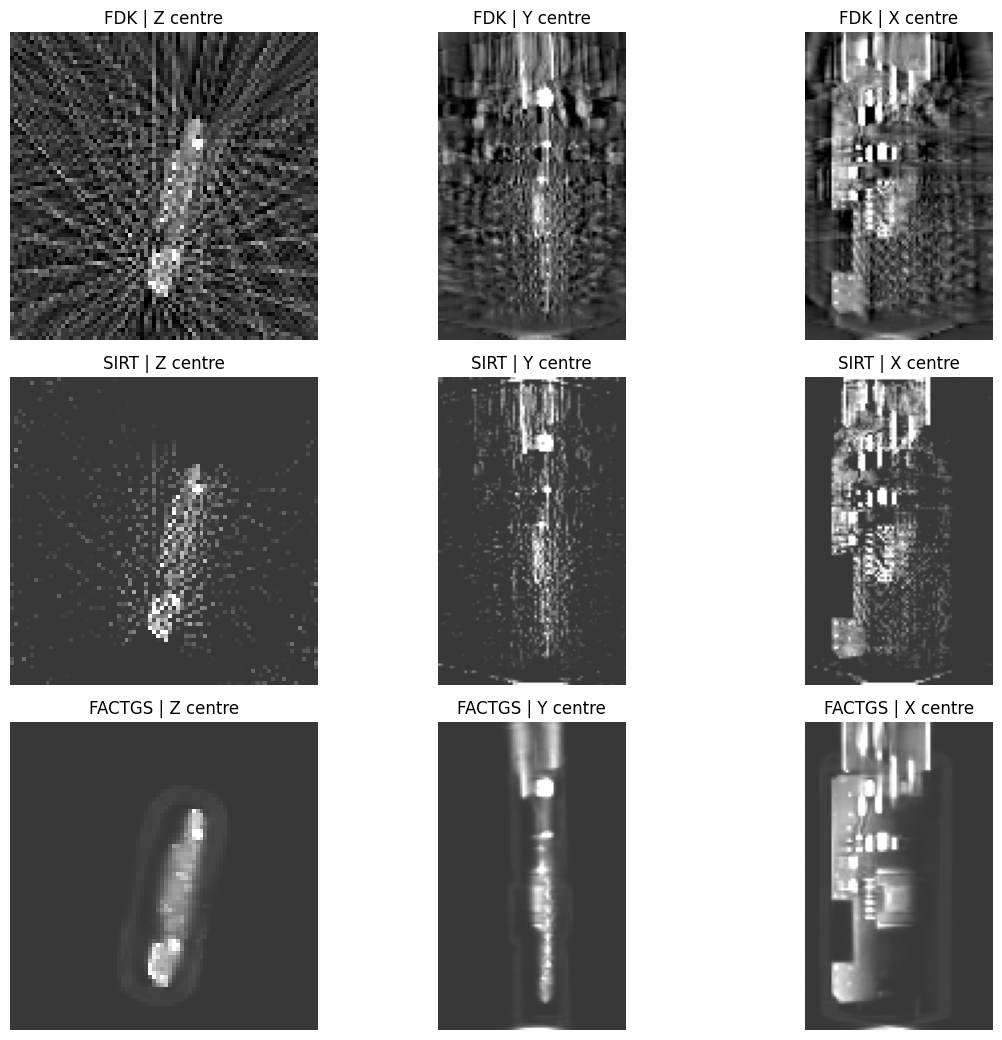

In [22]:
methods = list(reconstructed_volumes)
volumes = {m: reconstructed_volumes[m] for m in methods if m in reconstructed_volumes}
if volumes:
    low, high = np.percentile(np.concatenate([v.ravel()[::16] for v in volumes.values()]), [1, 99.5])
    fig, axes = plt.subplots(len(volumes), 3, figsize=(12, 3.5 * len(volumes)), squeeze=False)
    for row, (method, volume) in enumerate(volumes.items()):
        for axis, label in enumerate(['Z', 'Y', 'X']):
            view = np.take(volume, volume.shape[axis] // 2, axis=axis)
            axes[row, axis].imshow(view, cmap='gray', origin='lower', vmin=low, vmax=high)
            axes[row, axis].set_title(f'{method.upper()} | {label} centre')
            axes[row, axis].axis('off')
    plt.tight_layout()
    plt.show()


## 5. Compare view counts

Batch reconstruction is enabled by default (`RUN_ALL_VIEWS = True`): Run All reconstructs 25, 50 and 75 views, including a fresh run of the view count already reconstructed above. Set `RUN_ALL_VIEWS = False` to skip this section. Execute the preceding cells first to define the functions and shared metric range. Each run starts independently and uses the same 20 test views. Results are stored in `batch_results`. `BATCH_METHODS` inherits `RUN_FDK`, `RUN_SIRT` and `RUN_FACTGS` from Section 2.1; disabling FaCT-GS there also disables it here.


In [23]:
RUN_ALL_VIEWS = True
VIEW_COUNTS = [25, 50, 75]
BATCH_METHODS = [
    name for name, enabled in [
        ('fdk', RUN_FDK),
        ('sirt', RUN_SIRT),
        ('factgs', RUN_FACTGS),
    ] if enabled
]

if RUN_ALL_VIEWS:
    if not BATCH_METHODS:
        raise ValueError('Enable at least one reconstruction method in Section 2.1 or set RUN_ALL_VIEWS = False.')
    from datetime import datetime
    batch_output = CASE / 'runs_notebook' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
    batch_results = {}
    for view_count in VIEW_COUNTS:
        indices = np.asarray(train_splits[view_count])
        group_data = select_training_data(preprocessed, indices)
        _, sizes, counts = make_volume_grid(group_data.geometry)
        group_data, group_ig = normalize_geometry(group_data, sizes, counts)
        volumes, metrics = {}, {}
        batch_results[view_count] = dict(volumes=volumes, metrics=metrics)
        for method in BATCH_METHODS:
            print(f'{view_count} views | {method.upper()}')
            if method == 'fdk':
                volume = reconstruct_fdk(group_data, group_ig)
            elif method == 'sirt':
                volume, _ = reconstruct_sirt(group_data, group_ig, iterations=1000)
            elif method == 'factgs':
                volume, pairs = reconstruct_factgs(
                    group_data, group_ig, angles, projections, indices, test_indices,
                    batch_output / f'{view_count}views' / 'factgs',
                    steps=FACTGS_STEPS, gaussians=FACTGS_GAUSSIANS)
            else:
                raise ValueError(f'Unknown method: {method}')
            if method != 'factgs':
                pairs = project_cil_volume(volume, group_data, group_ig, projections, angles, test_indices)
            volumes[method] = volume
            metrics[method] = evaluate_projections(pairs)


25 views | FDK
25 views | SIRT
SIRT iteration 0/1000
SIRT iteration 100/1000
SIRT iteration 200/1000
SIRT iteration 300/1000
SIRT iteration 400/1000
SIRT iteration 500/1000
SIRT iteration 600/1000
SIRT iteration 700/1000
SIRT iteration 800/1000
SIRT iteration 900/1000
SIRT iteration 1000/1000
25 views | FACTGS
Loading Training Cameras
Loading Test Cameras
Data source path: in_memory_usb
Model save path: /home/yjm/USB-Sparse-View/runs_notebook/20261115_171616_549002/25views/factgs/run_q3zcyxd2
Initialize 10000 out of total 10000 Gaussians.
Using FDK reconstruction for initialization.
Reconstruction finished
Random sampling in an intensity volume using gradient as probability.
Initialize gaussians from 10000 estimated points
Use total variation loss


[STEP 20000] Saving Gaussians
FaCT-GS elapsed time: 139.626 seconds
50 views | FDK
50 views | SIRT
SIRT iteration 0/1000
SIRT iteration 100/1000
SIRT iteration 200/1000
SIRT iteration 300/1000
SIRT iteration 400/1000
SIRT iteration 500/1000
SIRT iteration 600/1000
SIRT iteration 700/1000
SIRT iteration 800/1000
SIRT iteration 900/1000
SIRT iteration 1000/1000
50 views | FACTGS
Loading Training Cameras
Loading Test Cameras
Data source path: in_memory_usb
Model save path: /home/yjm/USB-Sparse-View/runs_notebook/20261115_171616_549002/50views/factgs/run_3kxnl16v
Initialize 10000 out of total 10000 Gaussians.
Using FDK reconstruction for initialization.
Reconstruction finished
Random sampling in an intensity volume using gradient as probability.
Initialize gaussians from 10000 estimated points
Use total variation loss


[STEP 20000] Saving Gaussians
FaCT-GS elapsed time: 150.230 seconds
75 views | FDK
75 views | SIRT
SIRT iteration 0/1000
SIRT iteration 100/1000
SIRT iteration 200/1000
SIRT iteration 300/1000
SIRT iteration 400/1000
SIRT iteration 500/1000
SIRT iteration 600/1000
SIRT iteration 700/1000
SIRT iteration 800/1000
SIRT iteration 900/1000
SIRT iteration 1000/1000
75 views | FACTGS
Loading Training Cameras
Loading Test Cameras
Data source path: in_memory_usb
Model save path: /home/yjm/USB-Sparse-View/runs_notebook/20261115_171616_549002/75views/factgs/run_xzx7bf7r
Initialize 10000 out of total 10000 Gaussians.
Using FDK reconstruction for initialization.
Reconstruction finished
Random sampling in an intensity volume using gradient as probability.
Initialize gaussians from 10000 estimated points
Use total variation loss


[STEP 20000] Saving Gaussians
FaCT-GS elapsed time: 143.075 seconds


### 5.1 Summary metrics


In [24]:
if RUN_ALL_VIEWS:
    rows = ['| Training views | Method | Train PSNR | Train SSIM | Test PSNR | Test SSIM |',
            '| ---: | --- | ---: | ---: | ---: | ---: |']
    for view_count, result in batch_results.items():
        for method, scores in result['metrics'].items():
            train, test = scores['train'], scores['test']
            rows.append(
                f"| {view_count} | {method.upper()} | {train['psnr_mean_db']:.4f} | "
                f"{train['ssim_mean']:.4f} | {test['psnr_mean_db']:.4f} | {test['ssim_mean']:.4f} |")
    display(Markdown('\n'.join(rows)))


| Training views | Method | Train PSNR | Train SSIM | Test PSNR | Test SSIM |
| ---: | --- | ---: | ---: | ---: | ---: |
| 25 | FDK | 21.7513 | 0.4722 | 22.2558 | 0.4308 |
| 25 | SIRT | 28.7239 | 0.7046 | 26.9690 | 0.6383 |
| 25 | FACTGS | 27.9693 | 0.9481 | 27.3416 | 0.9367 |
| 50 | FDK | 24.7226 | 0.5724 | 24.0361 | 0.5279 |
| 50 | SIRT | 28.3567 | 0.7157 | 27.5251 | 0.6755 |
| 50 | FACTGS | 27.9190 | 0.9513 | 27.3434 | 0.9396 |
| 75 | FDK | 25.2809 | 0.6038 | 24.5890 | 0.5714 |
| 75 | SIRT | 28.2315 | 0.7200 | 27.6698 | 0.6887 |
| 75 | FACTGS | 28.6275 | 0.9533 | 27.9524 | 0.9427 |

### 5.2 Compare slices

Rows correspond to view counts and columns to reconstruction methods. Images show the central Z slice of each volume reconstructed from the training projections, using a shared display window.


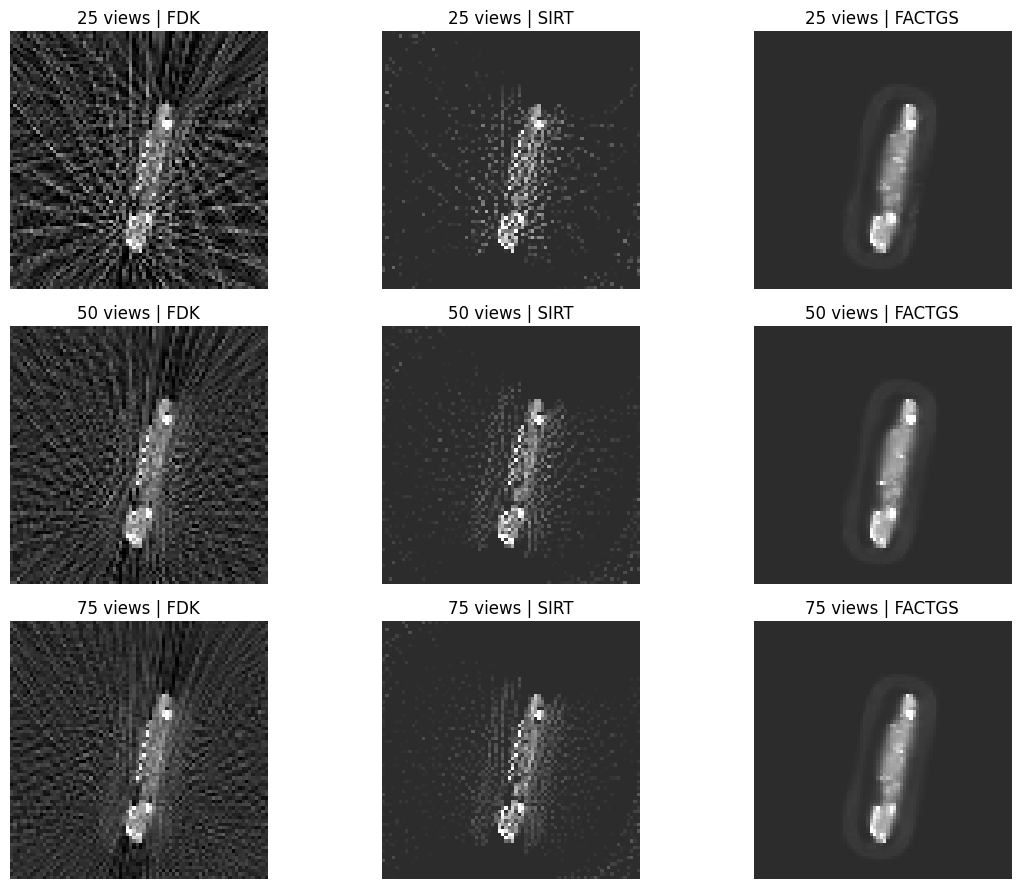

In [25]:
if RUN_ALL_VIEWS:
    samples = np.concatenate([
        volume.ravel()[::16]
        for result in batch_results.values() for volume in result['volumes'].values()
    ])
    low, high = np.percentile(samples, [1, 99.5])
    fig, axes = plt.subplots(len(VIEW_COUNTS), len(BATCH_METHODS),
                             figsize=(4 * len(BATCH_METHODS), 3 * len(VIEW_COUNTS)),
                             squeeze=False)
    for row, view_count in enumerate(VIEW_COUNTS):
        for col, method in enumerate(BATCH_METHODS):
            volume = batch_results[view_count]['volumes'][method]
            axes[row, col].imshow(volume[volume.shape[0] // 2],
                                  cmap='gray', origin='lower', vmin=low, vmax=high)
            axes[row, col].set_title(f'{view_count} views | {method.upper()}')
            axes[row, col].axis('off')
    plt.tight_layout()
    plt.show()


### Summary and conclusions

Across 25, 50 and 75 training views:

- **Training projections:** FaCT-GS achieves the highest SSIM at every view count. PSNR is highest for SIRT at 25/50 views and FaCT-GS at 75 views; both exceed FDK.
- **Test projections:** FaCT-GS achieves the highest SSIM, with a larger lead under sparser sampling. Its PSNR is close to SIRT and consistently higher than FDK.
- **Slices:** FDK shows strong streaks, while SIRT retains scattered artifacts. FaCT-GS gives the cleanest background and more continuous contours, but smooths some fine detail. Its visual advantage is most apparent at 25 views.

### Limitations

- **One dataset.** The comparison uses a single USB scan; the same trends may not hold for other samples or acquisition conditions.
- **Fixed reconstruction settings.** SIRT uses 1000 iterations and FaCT-GS uses 20000 training steps. Parameters were not separately tuned for each method and view count, so the results describe this configuration rather than each method's best achievable performance.
- **Smoothing versus detail.** FaCT-GS reduces background artifacts but also softens some fine structures. Higher projection SSIM does not imply that every local feature is more clearly resolved.

### Future work and extensions

1. Compare the three methods on our own scan data across different samples and acquisition conditions to assess how well the conclusions generalise.
2. Use gVXR to simulate projections at different noise levels and examine their effect on reconstruction quality.
3. Extend the experiments to limited-angle scans and compare FDK, SIRT and FaCT-GS under incomplete angular coverage.


## Licensing and references

Original contributions are [MIT-licensed](LICENSE.txt), copyright 2026 Yue Jiaming. FaCT-GS, its dependencies and the dataset retain their original terms. See the [FaCT-GS license and exclusions](https://github.com/PaPieta/fact-gs/blob/9b95ea9370055d9caf148899775173a3bdfe6d61/LICENSE.md); some components, including [R²-Gaussian](https://github.com/PaPieta/fact-gs/blob/9b95ea9370055d9caf148899775173a3bdfe6d61/fact_gs/r2_gaussian/LICENSE.md) and simple_knn, have research/non-commercial restrictions.

**References:** [CIL](https://github.com/TomographicImaging/CIL); Pieta et al., *FaCT-GS: Fast and Scalable CT Reconstruction with Gaussian Splatting* (2026), [citation](https://github.com/PaPieta/fact-gs#citation).
